# 03 · The Euler equations in 1D: Riemann problems and a Godunov-type solver

Notebook 01 used scalar conservation laws. Real gas dynamics couples three conserved quantities, has three kinds of
waves, and needs much more careful face fluxes. Here we build, from scratch and in ~80 lines of `jax.numpy`, the same
class of solver that diffhydro (and Athena, FLASH, RAMSES …) uses: **a Godunov-type finite-volume method with an
approximate Riemann solver, limited MUSCL reconstruction and an SSP Runge–Kutta integrator**.

**In this notebook you will:**
- write the Euler equations in conservative form and convert between primitive and conservative variables,
- dissect the **Riemann problem** (shock, contact, rarefaction) with an exact solver,
- implement the **Rusanov, HLL and HLLC** approximate Riemann solvers,
- reach second order with **MUSCL** reconstruction and see why slopes must be **limited**,
- validate on the **Sod shock tube** and measure convergence,
- differentiate the whole solver to **infer the initial pressure and the adiabatic index** from a noisy density profile.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
import tutorial_utils as tu

jax.config.update("jax_enable_x64", True) #since we'll be doing some accuracy tests later
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. The Euler equations

Mass, momentum and energy conservation for an inviscid ideal gas:

$$\partial_t \underbrace{\begin{pmatrix}\rho\\ \rho u\\ E\end{pmatrix}}_{U}
+ \partial_x \underbrace{\begin{pmatrix}\rho u\\ \rho u^2 + p\\ (E+p)\,u\end{pmatrix}}_{F(U)} = 0,
\qquad E = \frac{p}{\gamma-1} + \frac12\rho u^2 .$$

The solver *evolves* conservative variables $U$ (that's what keeps shocks right, notebook 01) but it is more natural
to *reconstruct and reason* in primitive variables $W = (\rho, u, p)$. The equation of state closes the system; the
sound speed is $c = \sqrt{\gamma p/\rho}$. Linearising shows three characteristic speeds $u - c,\ u,\ u + c$:
two acoustic waves and one that just advects (the **contact**, where density jumps but pressure and velocity do not).

In [2]:
def prim_to_cons(W, gamma):
    rho, u, p = W
    return jnp.stack([rho, rho * u, p / (gamma - 1) + 0.5 * rho * u ** 2])

def cons_to_prim(U, gamma):
    rho = U[0]; u = U[1] / rho
    return jnp.stack([rho, u, (gamma - 1) * (U[2] - 0.5 * rho * u ** 2)])

def phys_flux(W, gamma):
    rho, u, p = W
    E = p / (gamma - 1) + 0.5 * rho * u ** 2
    return jnp.stack([rho * u, rho * u ** 2 + p, (E + p) * u])

## 2. The Riemann problem

Godunov's insight (1959): with piecewise-constant cell averages, **every face is a Riemann problem**, an initial
discontinuity between two constant states $W_L$ and $W_R$. Its exact solution is self-similar in $x/t$ and consists of
a left wave (shock or rarefaction), the contact, and a right wave, separated by two "star" states that share
$p^*$ and $u^*$. $p^*$ is the root of a scalar equation $f_L(p) + f_R(p) + (u_R - u_L) = 0$, where each $f_K$ is the shock
(Rankine–Hugoniot) or rarefaction (isentropic) relation. `tutorial_utils.exact_riemann` implements Toro's
textbook algorithm (Toro, *Riemann Solvers and Numerical Methods for Fluid Dynamics*, ch. 4) in ~60 lines of numpy.

The classic test is **Sod's shock tube**: $(\rho, u, p) = (1, 0, 1)$ on the left and $(0.125, 0, 0.1)$ on the right.

star region: p* = 0.30313, u* = 0.92745


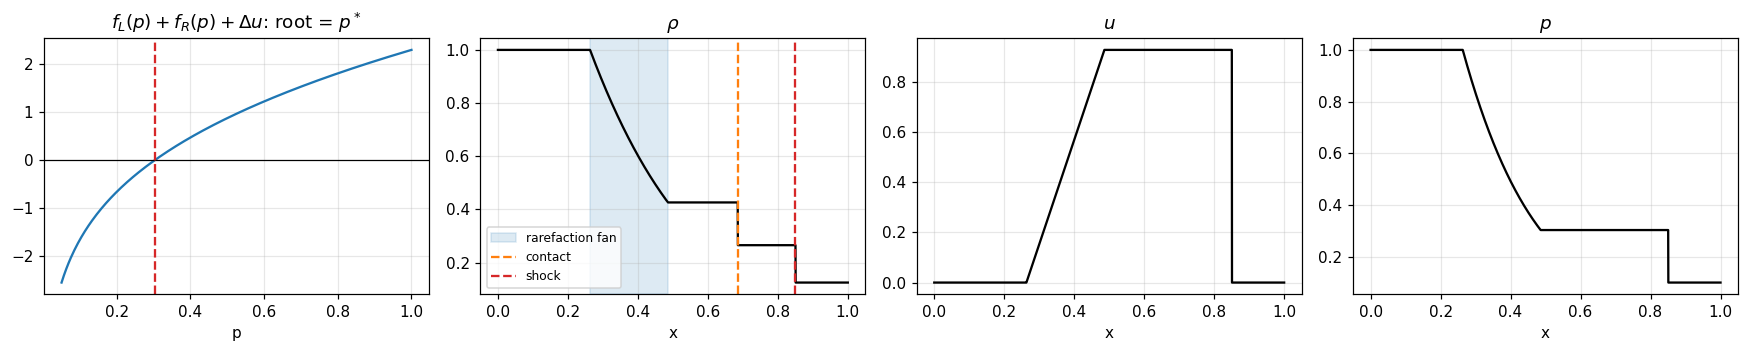

In [3]:
x_fine = np.linspace(0, 1, 2000)
t_sod = 0.2
rho_ex, u_ex, p_ex = tu.exact_riemann(1.0, 0.0, 1.0, 0.125, 0.0, 0.1, x_fine, t_sod)
p_star, u_star = tu.riemann_star(1.0, 0.0, 1.0, 0.125, 0.0, 0.1)
print(f"star region: p* = {p_star:.5f}, u* = {u_star:.5f}")

fig, axes = plt.subplots(1, 4, figsize=(16, 3.3))
p_grid = np.linspace(0.05, 1.0, 300)
f_sum = [tu._f_and_df(p, 1.0, 1.0, np.sqrt(1.4), 1.4)[0] + tu._f_and_df(p, 0.125, 0.1, np.sqrt(1.4 * 0.1 / 0.125), 1.4)[0]
         for p in p_grid]
axes[0].plot(p_grid, f_sum); axes[0].axhline(0, color="k", lw=0.8); axes[0].axvline(p_star, color="C3", ls="--")
axes[0].set_xlabel("p"); axes[0].set_title(r"$f_L(p) + f_R(p) + \Delta u$: root = $p^*$")
for ax, f, lab in zip(axes[1:], (rho_ex, u_ex, p_ex), (r"$\rho$", "$u$", "$p$")):
    ax.plot(x_fine, f, "k"); ax.set_title(lab); ax.set_xlabel("x")
xs = 0.5 + t_sod * np.array([-np.sqrt(1.4), u_star - np.sqrt(1.4) * p_star ** (0.4 / 2.8), u_star])
axes[1].axvspan(xs[0], xs[1], color="C0", alpha=0.15, label="rarefaction fan")
axes[1].axvline(xs[2], color="C1", ls="--", label="contact")
axes[1].axvline(0.5 + t_sod * 1.7522, color="C3", ls="--", label="shock")
axes[1].legend(fontsize=8)
plt.tight_layout()

From left to right: undisturbed gas, a smooth **rarefaction fan**, the left star state, the
**contact discontinuity** (density jumps, $u$ and $p$ continuous), the shocked right star state, and the **shock**.

## 3. Approximate Riemann solvers

The exact solver needs an iterative root-find at every face and every step. This is generally impractical for real applications and hard to implement efficiently on GPU. Production codes use cheap
approximations that only need an estimate of the fastest left- and right-going signal speeds $S_L, S_R$:

* **Rusanov** (local Lax–Friedrichs): one speed $s = \max(|u|+c)$; the flux of notebook 01. Very robust, very diffusive.
* **HLL** (Harten–Lax–van Leer 1983): two waves $S_L \le S_R$ bounding a *single* averaged star state. It resolves shocks well
  but smears the contact, because it does not know the contact exists.
* **HLLC** (Toro et al. 1994): restores the **C**ontact with a middle wave of speed $S^*$ and two star states. This is
  diffhydro's primary method for accuracy in both turbulent flows and shocks.

All are written on arrays of face states, so they are automatically vectorised across the grid.

In [4]:
def rusanov(WL, WR, gamma):
    cL, cR = jnp.sqrt(gamma * WL[2] / WL[0]), jnp.sqrt(gamma * WR[2] / WR[0])
    s = jnp.maximum(jnp.abs(WL[1]) + cL, jnp.abs(WR[1]) + cR)
    return 0.5 * (phys_flux(WL, gamma) + phys_flux(WR, gamma)) - 0.5 * s * (prim_to_cons(WR, gamma) - prim_to_cons(WL, gamma))

def hll(WL, WR, gamma):
    cL, cR = jnp.sqrt(gamma * WL[2] / WL[0]), jnp.sqrt(gamma * WR[2] / WR[0])
    SL = jnp.minimum(WL[1] - cL, WR[1] - cR); SR = jnp.maximum(WL[1] + cL, WR[1] + cR)
    FL, FR = phys_flux(WL, gamma), phys_flux(WR, gamma)
    UL, UR = prim_to_cons(WL, gamma), prim_to_cons(WR, gamma)
    F_hll = (SR * FL - SL * FR + SL * SR * (UR - UL)) / (SR - SL)
    return jnp.where(SL >= 0, FL, jnp.where(SR <= 0, FR, F_hll))

def hllc(WL, WR, gamma):
    rL, uL, pL = WL; rR, uR, pR = WR
    cL, cR = jnp.sqrt(gamma * pL / rL), jnp.sqrt(gamma * pR / rR)
    SL = jnp.minimum(uL - cL, uR - cR); SR = jnp.maximum(uL + cL, uR + cR)
    Ss = (pR - pL + rL * uL * (SL - uL) - rR * uR * (SR - uR)) / (rL * (SL - uL) - rR * (SR - uR))
    FL, FR = phys_flux(WL, gamma), phys_flux(WR, gamma)
    UL, UR = prim_to_cons(WL, gamma), prim_to_cons(WR, gamma)
    def star(U, r, u, p, S):
        fac = r * (S - u) / (S - Ss)
        return fac * jnp.stack([jnp.ones_like(r), Ss, U[2] / r + (Ss - u) * (Ss + p / (r * (S - u)))])
    FsL = FL + SL * (star(UL, rL, uL, pL, SL) - UL)
    FsR = FR + SR * (star(UR, rR, uR, pR, SR) - UR)
    return jnp.where(SL >= 0, FL, jnp.where(Ss >= 0, FsL, jnp.where(SR > 0, FsR, FR)))

## 4. Reconstruction, limiters and time integration

First-order Godunov uses the cell average on both sides of every face. **MUSCL** (van Leer 1979) reconstructs a
linear profile in each cell, $W_i(x) = W_i + \sigma_i (x - x_i)/\Delta x$, and feeds the extrapolated face values to the
Riemann solver. The slope must be "limited" as Godunov's theorem says no *linear* scheme above first order avoids
creating new extrema at discontinuities. A limiter is a nonlinear switch that uses the full slope in smooth regions and drops to
zero at extrema. Some simple examples include;

* **minmod**: the smaller of the left/right differences (most dissipative),
* **monotonised central (MC)**: $\min(2|\Delta_L|, 2|\Delta_R|, \tfrac12|\Delta_L+\Delta_R|)$ (sharper; diffhydro's `"MC"`).

Other common ones include van Leer, superbee, Koren, etc. (see diffhydro/solver/limiter.py)
For time integration we use **SSP-RK2** (Heun's method, a convex combination of Euler steps that preserves the
non-oscillatory property). In this example boundaries are *outflow* where we pad with copies of the edge cell (ghost cells).

In [5]:
def minmod(a, b):
    return jnp.where(a * b > 0, jnp.sign(a) * jnp.minimum(jnp.abs(a), jnp.abs(b)), 0.0)

def mc(a, b):
    return jnp.where(a * b > 0, jnp.sign(a) * jnp.minimum(jnp.minimum(2 * jnp.abs(a), 2 * jnp.abs(b)), 0.5 * jnp.abs(a + b)), 0.0)

def no_slope(a, b):
    return jnp.zeros_like(a)

def rhs(U, dx, gamma, riemann, limiter):
    W = cons_to_prim(U, gamma)
    Wg = jnp.pad(W, ((0, 0), (2, 2)), mode="edge")       # outflow boundaries: 2 ghost cells
    Wc = Wg[:, 1:-1]                                     # cells -1 .. N (one ghost each side)
    slope = limiter(Wc - Wg[:, :-2], Wg[:, 2:] - Wc)
    WL = Wc[:, :-1] + 0.5 * slope[:, :-1]                # left state at faces -1/2 .. N-1/2
    WR = Wc[:, 1:] - 0.5 * slope[:, 1:]
    F = riemann(WL, WR, gamma)
    return -(F[:, 1:] - F[:, :-1]) / dx

def ssprk2(U, dt, dx, gamma, riemann, limiter):
    U1 = U + dt * rhs(U, dx, gamma, riemann, limiter)
    return 0.5 * U + 0.5 * (U1 + dt * rhs(U1, dx, gamma, riemann, limiter))

def max_speed(U, gamma):
    W = cons_to_prim(U, gamma)
    return jnp.max(jnp.abs(W[1]) + jnp.sqrt(gamma * W[2] / W[0]))

def solve(W0, dx, t_end, gamma=1.4, riemann=hllc, limiter=mc, cfl=0.4):
    step = jax.jit(lambda U, dt: ssprk2(U, dt, dx, gamma, riemann, limiter))
    U, t = prim_to_cons(jnp.asarray(W0), gamma), 0.0
    while t < t_end - 1e-12:
        dt = min(cfl * dx / float(max_speed(U, gamma)), t_end - t)
        U = step(U, dt); t += dt
    return cons_to_prim(U, gamma)

## 5. The Sod shock tube

Let's compare first-order Rusanov / HLL / HLLC and second-order (MUSCL) HLLC against the exact solution with
$N = 200$ cells. We also try **unlimited** central slopes to see Godunov's theorem in action.

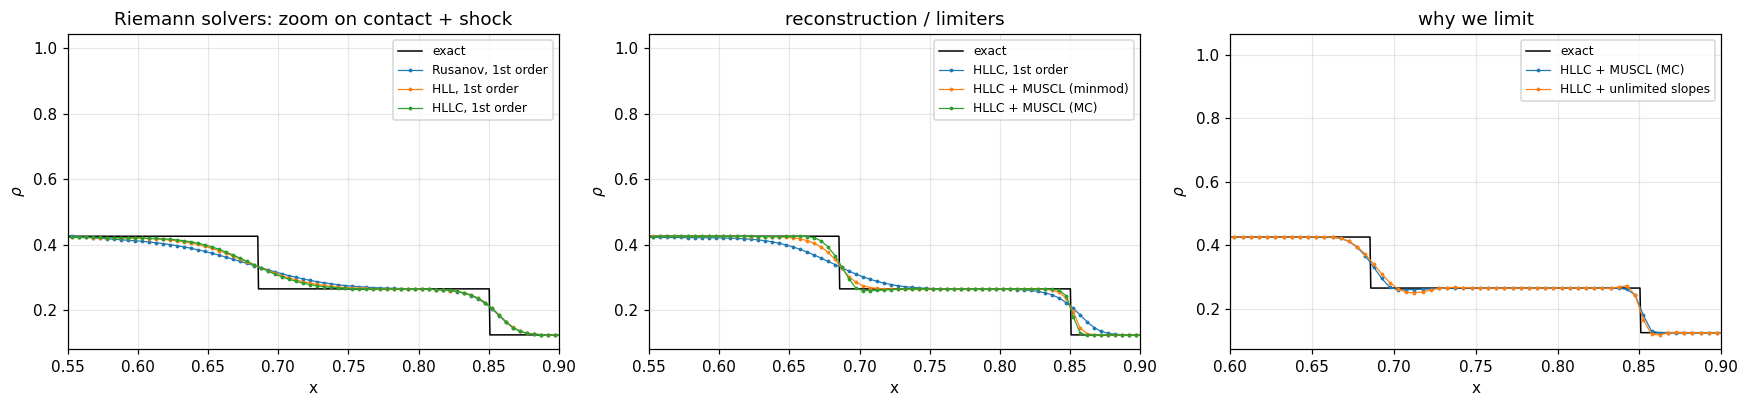

In [6]:
def sod_ic(N, pL=1.0):
    x = (np.arange(N) + 0.5) / N
    return x, np.stack([np.where(x < 0.5, 1.0, 0.125), np.zeros(N), np.where(x < 0.5, pL, 0.1)])

def central(a, b):          # unlimited slope (for demonstration only)
    return 0.5 * (a + b)

N = 200
x, W0 = sod_ic(N)
runs = {"Rusanov, 1st order": (rusanov, no_slope), "HLL, 1st order": (hll, no_slope),
        "HLLC, 1st order": (hllc, no_slope), "HLLC + MUSCL (minmod)": (hllc, minmod),
        "HLLC + MUSCL (MC)": (hllc, mc), "HLLC + unlimited slopes": (hllc, central)}
results = {k: np.asarray(solve(W0, 1.0 / N, t_sod, riemann=R, limiter=lim)) for k, (R, lim) in runs.items()}

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, keys in zip(axes, [list(runs)[:3], list(runs)[2:5], ["HLLC + MUSCL (MC)", "HLLC + unlimited slopes"]]):
    ax.plot(x_fine, rho_ex, "k", lw=1, label="exact")
    for k in keys:
        ax.plot(x, results[k][0], ".-", ms=3, lw=0.8, label=k)
    ax.legend(fontsize=8); ax.set_xlabel("x"); ax.set_ylabel(r"$\rho$")
axes[0].set_xlim(0.55, 0.9); axes[0].set_title("Riemann solvers: zoom on contact + shock")
axes[1].set_xlim(0.55, 0.9); axes[1].set_title("reconstruction / limiters")
axes[2].set_xlim(0.6, 0.9); axes[2].set_title("why we limit")
plt.tight_layout()

A few observations:

* Rusanov smears everything. HLL sharpens the shock; HLLC also sharpens the **contact** (around $x = 0.69$).
* MUSCL reconstruction cuts the width of every feature roughly in half, and MC is crisper than minmod.
* Without a limiter, the second-order scheme rings at the discontinuities: those wiggles are not physical.

### Convergence

For solutions with discontinuities, the L1 error converges more slowly than the formal order. Smeared discontinuities
contribute $\mathcal O(\Delta x)$ (shock) or $\mathcal O(\Delta x^{1/2})$ to $\mathcal O(\Delta x^{2/3})$ (contact, which is not self-steepening).

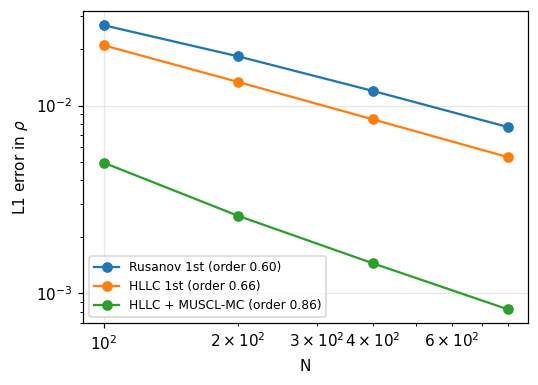

In [7]:
Ns = [100, 200, 400, 800]
schemes = {"Rusanov 1st": (rusanov, no_slope), "HLLC 1st": (hllc, no_slope), "HLLC + MUSCL-MC": (hllc, mc)}
errs = {k: [] for k in schemes}
for n in Ns:
    xn, W0n = sod_ic(n)
    rho_exact = tu.exact_riemann(1.0, 0.0, 1.0, 0.125, 0.0, 0.1, xn, t_sod)[0]
    for k, (R, lim) in schemes.items():
        errs[k].append(np.mean(np.abs(np.asarray(solve(W0n, 1.0 / n, t_sod, riemann=R, limiter=lim)[0]) - rho_exact)))

fig, ax = plt.subplots(figsize=(5, 3.6))
for k, e in errs.items():
    order = -np.polyfit(np.log(Ns), np.log(e), 1)[0]
    ax.loglog(Ns, e, "o-", label=f"{k} (order {order:.2f})")
ax.set_xlabel("N"); ax.set_ylabel(r"L1 error in $\rho$"); ax.legend(fontsize=8)
plt.tight_layout()

MUSCL-MC reaches a given accuracy with **~4× fewer cells** than first-order HLLC. In 3D that is ~64× less memory and
~256× less work, which is why every modern code is (at least) second order.

## 6. Differentiating through shocks: what was the initial state?

Now the inverse problem! Lets say someone ran a shock tube with an unknown left pressure $p_L$ and an unknown adiabatic
index $\gamma$ and measured a **noisy density profile** at $t = 0.2$. Can we recover $(p_L, \gamma)$ by gradient descent
*through* our solver?

For differentiability we make one pragmatic change. A **fixed time step** ($\Delta t = T/n_\text{steps}$, chosen safely below the
CFL limit for the whole parameter range) instead of the adaptive CFL step. The final time is then exactly $T$ for
every parameter value, and the loop is a `lax.scan` with a fixed length. We fit $\log p_L$ (so it stays positive)
and $\gamma$. This choice is mostly a limitation of JAX due to the compile-time restrictions and the way XLA-tracting works under the hood.

In [8]:
N = 200
x, _ = sod_ic(N)
T, nsteps = 0.2, 300
dt = T / nsteps          # max signal speed over the prior range is < 3.5, so CFL < 0.5 everywhere

def forward(theta):
    pL, gamma = jnp.exp(theta[0]), theta[1]
    W0 = jnp.stack([jnp.where(x < 0.5, 1.0, 0.125), jnp.zeros(N), jnp.where(x < 0.5, pL, 0.1)])
    U = jax.lax.scan(lambda U, _: (ssprk2(U, dt, 1.0 / N, gamma, hllc, mc), None),
                     prim_to_cons(W0, gamma), None, length=nsteps)[0]
    return cons_to_prim(U, gamma)[0]

theta_true = jnp.array([np.log(1.0), 1.4])
sigma_n = 0.01
data = forward(theta_true) + sigma_n * np.random.default_rng(0).standard_normal(N)

@jax.jit
def loss(theta):
    return jnp.mean((forward(theta) - data) ** 2) / sigma_n ** 2

# the whole loss landscape, batched with vmap
lp_grid, g_grid = np.linspace(np.log(0.3), np.log(3.0), 41), np.linspace(1.1, 1.8, 36)
LP, GG = np.meshgrid(lp_grid, g_grid)
landscape = np.asarray(jax.jit(jax.vmap(loss))(jnp.stack([LP.ravel(), GG.ravel()], 1))).reshape(LP.shape)

# Adam from a poor initial guess
vg = jax.jit(jax.value_and_grad(loss))
theta, st, path, hist = jnp.array([np.log(0.4), 1.7]), tu.adam_init(jnp.zeros(2)), [], []
for i in range(150):
    l, g = vg(theta)
    path.append(np.asarray(theta)); hist.append(float(l))
    theta, st = tu.adam_step(theta, g, st, lr=0.03)
path = np.array(path)
print(f"recovered p_L = {np.exp(theta[0]):.4f} (true 1.0),  gamma = {theta[1]:.4f} (true 1.4),  chi^2/cell = {hist[-1]:.3f}")

recovered p_L = 1.0036 (true 1.0),  gamma = 1.4015 (true 1.4),  chi^2/cell = 0.915


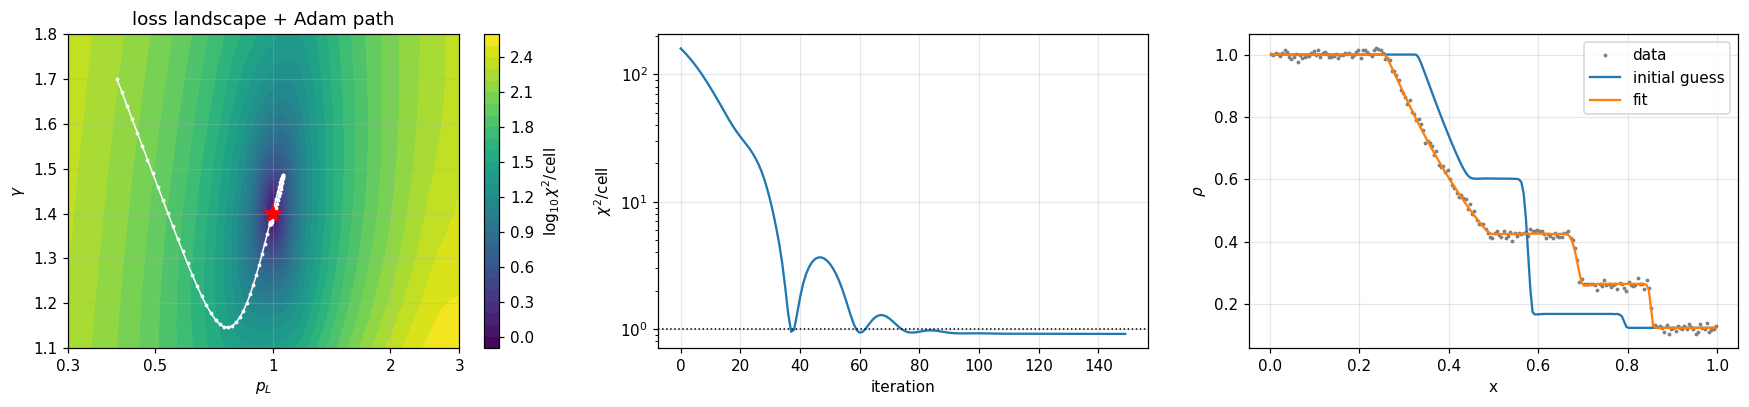

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
cs = axes[0].contourf(np.exp(LP), GG, np.log10(landscape), levels=30, cmap="viridis")
plt.colorbar(cs, ax=axes[0], label=r"$\log_{10}\chi^2$/cell")
axes[0].plot(np.exp(path[:, 0]), path[:, 1], "w.-", ms=3, lw=1); axes[0].plot(1.0, 1.4, "r*", ms=12)
axes[0].set_xscale("log"); axes[0].set_xticks([0.3, 0.5, 1, 2, 3], ["0.3", "0.5", "1", "2", "3"]); axes[0].minorticks_off()
axes[0].set_xlabel("$p_L$"); axes[0].set_ylabel(r"$\gamma$"); axes[0].set_title("loss landscape + Adam path")
axes[1].semilogy(hist); axes[1].axhline(1, color="k", ls=":", lw=1)
axes[1].set_xlabel("iteration"); axes[1].set_ylabel(r"$\chi^2$/cell")
axes[2].plot(x, data, ".", ms=3, color="gray", label="data")
axes[2].plot(x, forward(path[0]), label="initial guess"); axes[2].plot(x, forward(theta), label="fit")
axes[2].legend(); axes[2].set_xlabel("x"); axes[2].set_ylabel(r"$\rho$")
plt.tight_layout()

The landscape is a long, narrow valley. The shock position and plateau heights pin down $p_L$ tightly, while
$\gamma$ is much less constrained: changing it mostly reshapes the rarefaction fan and shifts the plateaus slightly.
Adam first heads downhill in $p_L$, overshoots in $\gamma$, then follows the valley floor to the truth within the noise.

### Are gradients through shocks trustworthy?

A shock is a discontinuity, and the discrete shock *moves in jumps of one cell*. Is $\partial\mathcal L/\partial p_L$
meaningful? Let's sweep $p_L$ finely at two resolutions and look at both the loss and its autodiff gradient.

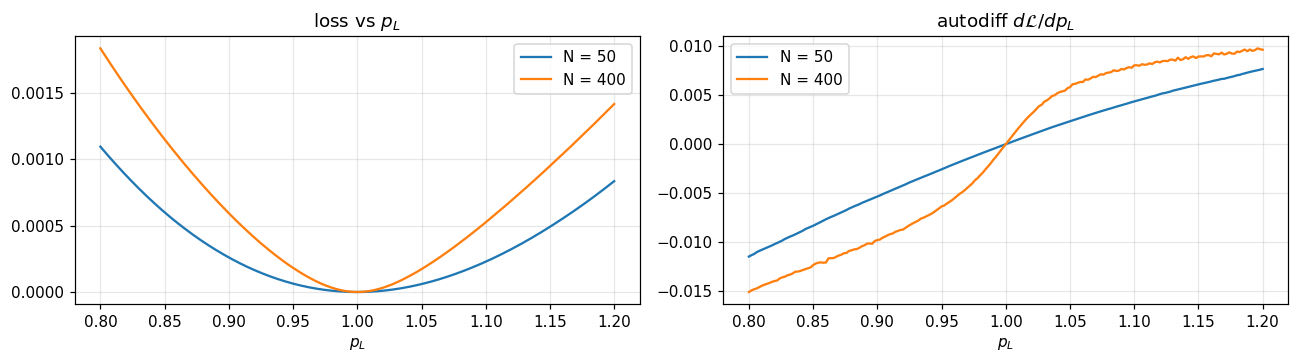

In [10]:
def make_loss_1d(Nc):
    xc = (np.arange(Nc) + 0.5) / Nc
    ns = int(nsteps * Nc / 200); dtc = T / ns
    def fwd(pL):
        W0 = jnp.stack([jnp.where(xc < 0.5, 1.0, 0.125), jnp.zeros(Nc), jnp.where(xc < 0.5, pL, 0.1)])
        U = jax.lax.scan(lambda U, _: (ssprk2(U, dtc, 1.0 / Nc, 1.4, hllc, mc), None),
                         prim_to_cons(W0, 1.4), None, length=ns)[0]
        return cons_to_prim(U, 1.4)[0]
    ref = fwd(1.0)
    return jax.jit(jax.vmap(jax.value_and_grad(lambda pL: jnp.mean((fwd(pL) - ref) ** 2))))

pLs = jnp.linspace(0.8, 1.2, 201)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for Nc in (50, 400):
    L_, dL_ = make_loss_1d(Nc)(pLs)
    axes[0].plot(pLs, L_, label=f"N = {Nc}"); axes[1].plot(pLs, dL_, label=f"N = {Nc}")
axes[0].set_title("loss vs $p_L$"); axes[1].set_title(r"autodiff $d\mathcal{L}/dp_L$")
for ax in axes: ax.set_xlabel("$p_L$"); ax.legend()
plt.tight_layout()

The loss is smooth at the scale of the valley, and the gradient points the right way at both resolutions. Up close
the $N=400$ gradient has small **ripples**: the limiters switch, and the steep discrete shock profile hops from cell to cell
as $p_L$ changes, so the loss is only piecewise smooth (notebook 02, pitfall (c)). At $N=50$ the shock is smeared over
more of the (coarse) domain and the ripples are averaged out. Either way the ripples are tiny compared with the trend.
Integrated observables like an L2 misfit over many cells average the jumps out, and Adam's momentum averages further,
so gradient-based fitting through shocks works well in practice.

## Summary and what's next

* The Euler equations are a system of conservation laws with three waves; **Godunov** methods solve a Riemann problem at each face.
* **HLLC + limited MUSCL + SSP-RK** is the standard recipe: sharp shocks *and* contacts, no spurious oscillations.
* The whole solver is a differentiable JAX function. With a fixed time step we can **infer physical parameters
  through shocks** and plot complete loss landscapes with `vmap`.

Our hand-written solver is ~80 lines but 1D only, with one equation of state and no physics modules. **Notebook 04**
switches to **diffhydro** with the same building blocks (HLLC, MUSCL, limiters, RK integrators) as configurable components,
in 1D, 2D and 3D, sharded across GPUs, with gravity, cooling, MHD … and still differentiable.